# Assignment 14: Dimensionality Reduction using PCA (Principal Component Analysis)
**Aim:** Reduce feature dimensionality from 3 features (`'Age'`, `'Annual Income (k$)'`, `'Spending Score (1-100)'`) down to 2 components (`"PC1"` and `"PCS2"`) using PCA on the Mall Customers dataset. Print and plot the explained variance ratio alongside a 2D scatter plot of the reduced features.  
**Tools / Libraries:** `pandas`, `numpy`, `matplotlib`, `seaborn`, `scikit-learn` (`sklearn.decomposition.PCA`, `sklearn.preprocessing.StandardScaler`)  
**Programming Platform / Language:** Jupyter Notebook, Python

## Theory & Task Overview

### Principal Component Analysis (PCA)
PCA is an unsupervised linear dimensionality reduction technique that transforms a large set of correlated variables into a smaller set of uncorrelated variables called **principal components**, while retaining as much variation/information as possible.
* **Why scale data before PCA?** PCA is sensitive to the relative scaling of original features (e.g., Age ranges from 18-70, while Income ranges from 15-140). Standardization ensures all features contribute equally to the variance.
* **Target Features:** 
  1. `Age`
  2. `Annual Income (k$)`
  3. `Spending Score (1-100)`
* **Reduced Components:** `PC1` and `PCS2` (2D subspace).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# 1. Load the Mall Customers dataset
df = pd.read_csv('Mall_Customers.csv')

# 2. Select the 3 features for dimensionality reduction
feature_cols = ['Age', 'Annual Income (k$)', 'Spending Score (1-100)']
X = df[feature_cols]

# 3. Standardize features (mean=0, variance=1)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Original Data Shape:", X.shape)
print("Data scaled successfully for PCA!")

Original Data Shape: (200, 3)
Data scaled successfully for PCA!


---
## Step 2: Applying PCA (Reducing 3D to 2D)
We project the 3-dimensional scaled data onto 2 principal components named **"PC1"** and **"PCS2"**.

In [2]:
# 1. Initialize PCA with 2 components
pca = PCA(n_components=2)

# 2. Fit and transform the scaled data
X_pca = pca.fit_transform(X_scaled)

# 3. Create a DataFrame for the reduced features
pca_df = pd.DataFrame(X_pca, columns=['PC1', 'PCS2'])
df['PC1'] = pca_df['PC1']
df['PCS2'] = pca_df['PCS2']

# 4. Extract Explained Variance Ratio
evr = pca.explained_variance_ratio_

# Print Explained Variance Ratio results
print("=" * 50)
print("       PCA EXPLAINED VARIANCE RATIO RESULTS       ")
print("=" * 50)
print(f"Explained Variance Ratio of PC1  : {evr[0]*100:.2f}%")
print(f"Explained Variance Ratio of PCS2 : {evr[1]*100:.2f}%")
print(f"Total Cumulative Variance Retained: {np.sum(evr)*100:.2f}%")
print("=" * 50)

       PCA EXPLAINED VARIANCE RATIO RESULTS       
Explained Variance Ratio of PC1  : 44.27%
Explained Variance Ratio of PCS2 : 33.31%
Total Cumulative Variance Retained: 77.57%


---
## Step 3: Visualizing PCA Results
We plot:
1. **Explained Variance Ratio Bar Plot:** Showing individual and cumulative variance captured by PC1 and PCS2.
2. **2D Scatter Plot:** Visualizing the customers in the newly reduced 2D feature space (`PC1` vs `PCS2`).

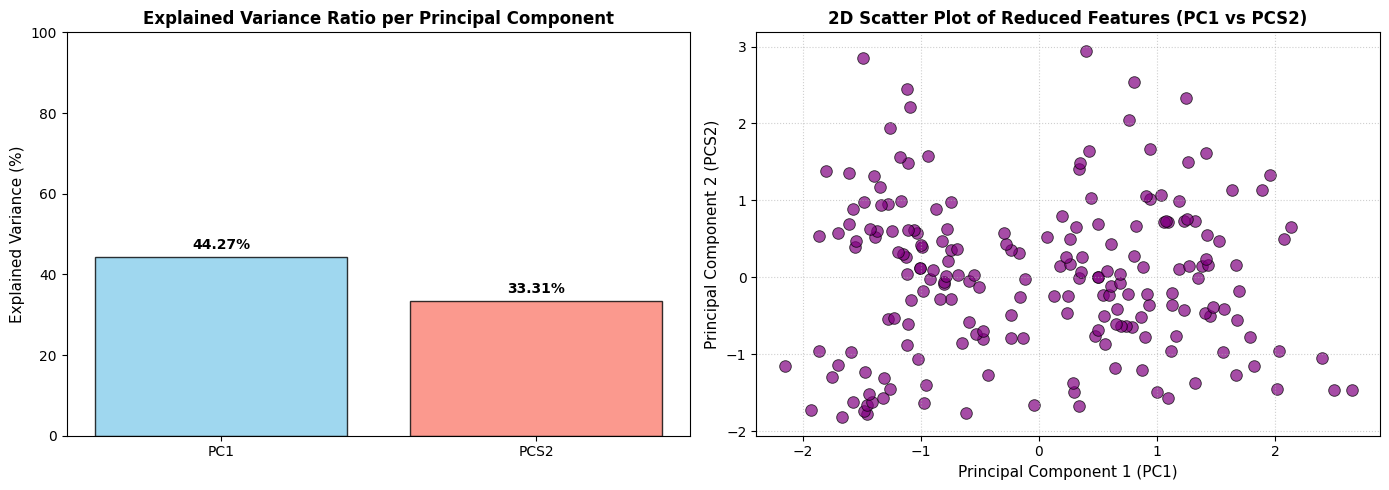

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Explained Variance Ratio Bar Plot
components = ['PC1', 'PCS2']
axes[0].bar(components, evr * 100, color=['skyblue', 'salmon'], edgecolor='black', alpha=0.8)
axes[0].set_title('Explained Variance Ratio per Principal Component', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Explained Variance (%)', fontsize=11)
axes[0].set_ylim(0, 100)

for i, v in enumerate(evr * 100):
    axes[0].text(i, v + 2, f"{v:.2f}%", ha='center', fontweight='bold')

# Plot 2: 2D Scatter Plot of PC1 vs PCS2
sns.scatterplot(
    x='PC1', 
    y='PCS2', 
    data=df, 
    ax=axes[1], 
    color='purple', 
    s=70, 
    alpha=0.7, 
    edgecolor='k'
)
axes[1].set_title('2D Scatter Plot of Reduced Features (PC1 vs PCS2)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Principal Component 1 (PC1)', fontsize=11)
axes[1].set_ylabel('Principal Component 2 (PCS2)', fontsize=11)
axes[1].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()